In [2]:
import os
import random
import numpy as np
import rasterio
from skimage.transform import resize
from scipy.ndimage import rotate
import tensorflow as tf
from tensorflow.keras.utils import Sequence, to_categorical
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, BatchNormalization, Concatenate
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# -----------------------------
# Configuration
# -----------------------------
IMG_HEIGHT = 256
IMG_WIDTH = 256
BATCH_SIZE = 8
EPOCHS = 500

IMG_DIR = "../../data/tiled_data/images"
MASK_DIR = "../../data/tiled_data/masks"
MODEL_DIR = "models_multiclass"
os.makedirs(MODEL_DIR, exist_ok=True)

# -----------------------------
# Pre-Scan: Dynamic Label Discovery
# -----------------------------
print("Scanning masks for unique labels...")
mask_files = [f for f in os.listdir(MASK_DIR) if f.endswith(".tif")]
if not mask_files:
    raise FileNotFoundError(f"No .tif files found in {MASK_DIR}")

unique_labels = set()
for f in mask_files:
    with rasterio.open(os.path.join(MASK_DIR, f)) as src:
        band = src.read(1)
        unique_labels.update(np.unique(band))

LABEL_LIST = sorted(list(unique_labels))
N_CLASSES = len(LABEL_LIST)
LABEL_MAP = {val: i for i, val in enumerate(LABEL_LIST)}
print(f"Detected {N_CLASSES} classes: {LABEL_LIST}")
print(f"Training Map (Original -> Internal): {LABEL_MAP}")

# -----------------------------
# Custom Metrics
# -----------------------------
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def iou_score(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

Scanning masks for unique labels...
Detected 10 classes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 99]
Training Map (Original -> Internal): {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 8: 7, 9: 8, 99: 9}


In [3]:
# -----------------------------
# Data Generator
# -----------------------------
class RasterDataGenerator(Sequence):
    def __init__(self, img_dir, mask_dir, img_files, mask_files, batch_size=BATCH_SIZE, shuffle=True, augment=True, **kwargs):
        super().__init__(**kwargs)
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.img_files = img_files
        self.mask_files = mask_files
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment

        mask_set = set(mask_files)
        self.valid_indices = [i for i, f in enumerate(img_files) if f in mask_set]
        print(f"Generator initialized with {len(self.valid_indices)} matching pairs.")

        self.indices = np.array(self.valid_indices)
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        imgs, masks = [], []

        for i in batch_idx:
            file_name = self.img_files[i]
            with rasterio.open(os.path.join(self.img_dir, file_name)) as src:
                img = src.read([1,2,3]).transpose(1,2,0).astype("float32")
            with rasterio.open(os.path.join(self.mask_dir, file_name)) as src:
                mask = src.read(1)

            img = resize(img, (IMG_HEIGHT, IMG_WIDTH), preserve_range=True)
            mask = resize(mask, (IMG_HEIGHT, IMG_WIDTH), order=0, preserve_range=True, anti_aliasing=False)

            if self.augment:
                if random.random() < 0.5:
                    img, mask = np.flipud(img), np.flipud(mask)
                if random.random() < 0.5:
                    angle = random.uniform(-15, 15)
                    img = rotate(img, angle, reshape=False, order=1, mode="reflect")
                    mask = rotate(mask, angle, reshape=False, order=0, mode="nearest")

            img = img / 255.0
            mapped_mask = np.zeros(mask.shape, dtype="int32")
            for raw_val, idx_map in LABEL_MAP.items():
                mapped_mask[mask == raw_val] = idx_map

            imgs.append(img)
            masks.append(to_categorical(mapped_mask, num_classes=N_CLASSES))

        return np.array(imgs), np.array(masks)

In [5]:
# -----------------------------
# U-Net Model
# -----------------------------
def build_unet(n_classes):
    inputs = Input((IMG_HEIGHT, IMG_WIDTH, 3))
    def conv_block(x, f):
        x = Conv2D(f, 3, padding="same", activation="relu")(x)
        x = BatchNormalization()(x)
        x = Conv2D(f, 3, padding="same", activation="relu")(x)
        return BatchNormalization()(x)
    s1 = conv_block(inputs, 64)
    p1 = MaxPooling2D((2,2))(s1)
    s2 = conv_block(p1, 128)
    p2 = MaxPooling2D((2,2))(s2)
    s3 = conv_block(p2, 256)
    p3 = MaxPooling2D((2,2))(s3)
    b1 = conv_block(p3, 512)
    d1 = Conv2DTranspose(256, 2, strides=2, padding="same")(b1)
    d1 = Concatenate()([d1, s3])
    d1 = conv_block(d1, 256)
    d2 = Conv2DTranspose(128, 2, strides=2, padding="same")(d1)
    d2 = Concatenate()([d2, s2])
    d2 = conv_block(d2, 128)
    d3 = Conv2DTranspose(64, 2, strides=2, padding="same")(d2)
    d3 = Concatenate()([d3, s1])
    d3 = conv_block(d3, 64)
    outputs = Conv2D(n_classes, 1, activation="softmax")(d3)
    return Model(inputs, outputs)

In [6]:
# -----------------------------
# Train-Validation Split
# -----------------------------
all_img = sorted([f for f in os.listdir(IMG_DIR) if f.endswith(".tif")])
all_msk = sorted([f for f in os.listdir(MASK_DIR) if f.endswith(".tif")])
combined = list(zip(all_img, all_msk))
random.shuffle(combined)
split_idx = int(len(combined) * 0.8)
train_pairs = combined[:split_idx]
val_pairs = combined[split_idx:]
train_imgs, train_msks = zip(*train_pairs)
val_imgs, val_msks = zip(*val_pairs)

train_gen = RasterDataGenerator(IMG_DIR, MASK_DIR, train_imgs, train_msks)
val_gen = RasterDataGenerator(IMG_DIR, MASK_DIR, val_imgs, val_msks, shuffle=False, augment=False)


Generator initialized with 820 matching pairs.
Generator initialized with 206 matching pairs.


In [7]:
# -----------------------------
# Callbacks
# -----------------------------
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
checkpoint = ModelCheckpoint(filepath=os.path.join(MODEL_DIR, "best_unet_model.keras"),
                             monitor='val_loss', save_best_only=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6, verbose=1)

In [8]:
# -----------------------------
# Compile & Train
# -----------------------------
model = build_unet(N_CLASSES)
model.compile(optimizer="adam", loss="categorical_crossentropy",
              metrics=["accuracy", dice_coef, iou_score])

history = model.fit(train_gen,
                    validation_data=val_gen,
                    epochs=EPOCHS,
                    callbacks=[early_stop, checkpoint, reduce_lr])


Epoch 1/500
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6530 - dice_coef: 0.5310 - iou_score: 0.3749 - loss: 1.1801
Epoch 1: val_loss improved from inf to 1.38557, saving model to models_multiclass\best_unet_model.keras
103/103 ━━━━━━━━━━━━━━━━━━━━ 420s 4s/step - accuracy: 0.6536 - dice_coef: 0.5316 - iou_score: 0.3754 - loss: 1.1777 - val_accuracy: 0.5165 - val_dice_coef: 0.4220 - val_iou_score: 0.2712 - val_loss: 1.3856 - learning_rate: 0.0010
Epoch 2/500
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7575 - dice_coef: 0.6451 - iou_score: 0.4780 - loss: 0.7714
Epoch 2: val_loss did not improve from 1.38557
103/103 ━━━━━━━━━━━━━━━━━━━━ 393s 4s/step - accuracy: 0.7575 - dice_coef: 0.6452 - iou_score: 0.4781 - loss: 0.7712 - val_accuracy: 0.2764 - val_dice_coef: 0.2572 - val_iou_score: 0.1485 - val_loss: 2.2633 - learning_rate: 0.0010
Epoch 3/500
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7663 - dice_coef: 0.6706 - iou_score: 0.5062 - loss: 0.7139
Epoch 3: va

In [9]:
# -----------------------------
# Save Final Model
# -----------------------------
save_path = os.path.join(MODEL_DIR, "unet_waste_mapping_model_final.keras")
model.save(save_path)
print(f"Final model saved at {save_path}")

Final model saved at models_multiclass\unet_waste_mapping_model_final.keras


In case, we are re-running, and we have skipped model building, lets load a model from above

In [1]:
import keras
# Import your custom functions here
# from your_script import dice_coef, iou_score 

multiclassmodel_path = r"models_multiclass\best_unet_model.keras"
binarymodel_path = r"models_binary\best_unet_binary.keras"
# Define the custom objects mapping
custom_dict = {
    "dice_coef": dice_coef,
    "iou_score": iou_score
}

# Load the model with the custom_objects parameter
multiclass_model = keras.models.load_model(multiclassmodel_path, custom_objects=custom_dict)
binary_model = keras.models.load_model(binarymodel_path, custom_objects=custom_dict)

print(f"Binary Input: {binary_model.input_shape}")
print(f"Multiclass Input: {multiclass_model.input_shape}")

NameError: name 'dice_coef' is not defined

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# 1. Define the descriptive labels in the EXACT order of your model's indices
# Based on your provided list:
target_names = [
    "Waste",
    "Soil",
    "Vegetation",
    "Built-up surface",
    "Built-up surface (paved)",
    "Water Body",
    "Natural Surface - rocks",
    "Non-persistent object",
    "Ancillary class"
]

# 2. Evaluation Loop
y_true_all = []
y_pred_all = []
eval_model = multiclass_model 

print("Running deep-dive evaluation on validation set...")
for i in range(len(val_gen)):
    x_batch, y_batch = val_gen[i]
    preds = eval_model.predict(x_batch, verbose=0)
    
    # Argmax handles the one-hot to index conversion
    y_true_all.append(np.argmax(y_batch, axis=-1).ravel())
    y_pred_all.append(np.argmax(preds, axis=-1).ravel())

y_true_flat = np.concatenate(y_true_all)
y_pred_flat = np.concatenate(y_pred_all)

# 3. Print Report
print("\n--- PER-CLASS EVALUATION ---")

# First, let's see what unique values are actually in your data
unique_classes = np.unique(np.concatenate([y_true_flat, y_pred_flat]))
print(f"Unique classes found in data: {unique_classes}")

# Fix: If you have 10 classes, we need to make sure target_names matches.
# If you don't know what the 10th class is yet, you can use this to prevent the crash:
if len(unique_classes) != len(target_names):
    print(f"Warning: Found {len(unique_classes)} classes but only {len(target_names)} names.")
    # This generates generic names for the missing slots
    extended_names = [target_names[i] if i < len(target_names) else f"Unknown Class {i}" 
                      for i in range(len(unique_classes))]
    print(classification_report(y_true_flat, y_pred_flat, target_names=extended_names))
else:
    print(classification_report(y_true_flat, y_pred_flat, target_names=target_names))

# 4. Confusion Matrix as Table (DataFrame)
cm = confusion_matrix(y_true_flat, y_pred_flat)

# Create a temporary list of names that matches the actual matrix size
actual_num_classes = cm.shape[0]
temp_names = [target_names[i] if i < len(target_names) else f"Unknown_Class_{i}" 
              for i in range(actual_num_classes)]

cm_df = pd.DataFrame(
    cm, 
    index=[f"Actual {name}" for name in temp_names], 
    columns=[f"Pred {name}" for name in temp_names]
)

print("\n--- CONFUSION MATRIX TABLE ---")
print(cm_df.to_string())

NameError: name 'multiclass_model' is not defined

: 

In [14]:
# Assuming your cm_df is already created as per your snippet:

# 1. Define the filename
file_name = "Multiclass_Model_Confusion_Matrix.xlsx"

# 2. Save to Excel
# index=True is important here because your "Actual" labels are in the index
cm_df.to_excel(file_name, index=True, sheet_name='Confusion_Matrix')

print(f"Success! Confusion matrix saved as: {file_name}")

Success! Confusion matrix saved as: Multiclass_Model_Confusion_Matrix.xlsx


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Choose which model to evaluate
eval_model = multiclass_model  # Using the multiclass one you just loaded

y_true_all = []
y_pred_all = []

print(f"Running evaluation for {len(val_gen)} batches...")

for i in range(len(val_gen)):
    x_batch, y_batch = val_gen[i]
    
    # Predict
    preds = eval_model.predict(x_batch, verbose=0)
    
    # ravel() turns the 2D image mask into a 1D array of pixels
    y_true_all.append(np.argmax(y_batch, axis=-1).ravel())
    y_pred_all.append(np.argmax(preds, axis=-1).ravel())

# Concatenate all batches into long pixel-wise arrays
y_true_flat = np.concatenate(y_true_all)
y_pred_flat = np.concatenate(y_pred_all)

# 2. Map indices back to original labels
# Ensure LABEL_LIST matches the order used during training/generator creation
target_names = [f"Class {label}" for label in LABEL_LIST]

# 3. Print the Classification Report
print("\n--- PER-CLASS EVALUATION ---")
report = classification_report(y_true_flat, y_pred_flat, target_names=target_names)
print(report)

Running evaluation for 26 batches...

--- PER-CLASS EVALUATION ---


C:\Users\Peter\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Peter\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

     Class 1       0.79      0.80      0.79    629572
     Class 2       0.90      0.85      0.87   3768770
     Class 3       0.92      0.96      0.94   6972772
     Class 4       0.96      0.94      0.95   1384529
     Class 5       0.83      0.76      0.79    312982
     Class 6       0.73      0.64      0.68    131402
     Class 7       0.85      0.40      0.55     49025
     Class 8       0.69      0.47      0.56     97306
     Class 9       0.54      0.61      0.58    151549
    Class 99       0.00      0.00      0.00      2509

    accuracy                           0.90  13500416
   macro avg       0.72      0.64      0.67  13500416
weighted avg       0.90      0.90      0.90  13500416



C:\Users\Peter\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Visualizations 

On the same validation data test perfomance of a purely binary model

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import gc

# 1. Identify the Correct Index
# If your LABEL_LIST is [1, 2, 3, 4, 5, 7, 8, 9, 99]
# Class '1' is at index 0.
target_class_value = 1
target_index = LABEL_LIST.index(target_class_value) 

eval_model = binary_model 
target_names = ["Background/Other", f"Class {target_class_value} (Index {target_index})"]

y_true_all = []
y_pred_all = []

print(f"Isolating Label {target_class_value} (mapped to Index {target_index})")

for i in range(len(val_gen)):
    x_batch, y_batch = val_gen[i]
    preds = eval_model.predict(x_batch, verbose=0)
    
    # --- GROUND TRUTH HANDLING ---
    # y_batch is (B, H, W, N_CLASSES)
    # Use argmax to get the internal indices (0, 1, 2...)
    y_true_indices = np.argmax(y_batch, axis=-1)
    
    # Now isolate ONLY the pixels that match our target index
    y_true_binary = (y_true_indices == target_index).astype(int)

    # --- PREDICTION HANDLING ---
    if preds.shape[-1] == 1:
        # Sigmoid output
        y_pred_binary = (preds > 0.5).astype(int)
    else:
        # Softmax output (assuming index 1 of the binary model is the positive class)
        y_pred_binary = np.argmax(preds, axis=-1)

    y_true_all.append(y_true_binary.ravel())
    y_pred_all.append(y_pred_binary.ravel())
    
    if i % 10 == 0: gc.collect()

# 3. Combine and Report
y_true_flat = np.concatenate(y_true_all)
y_pred_flat = np.concatenate(y_pred_all)

print("\n--- REWORKED BINARY EVALUATION ---")
print(classification_report(y_true_flat, y_pred_flat, target_names=target_names))

Isolating Label 1 (mapped to Index 0)

--- REWORKED BINARY EVALUATION ---
                   precision    recall  f1-score   support

 Background/Other       0.98      0.99      0.99  12808259
Class 1 (Index 0)       0.86      0.69      0.76    692157

         accuracy                           0.98  13500416
        macro avg       0.92      0.84      0.88  13500416
     weighted avg       0.98      0.98      0.98  13500416



In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import gc

# 1. Setup Labels
full_labels = [
    "Waste", "Soil", "Vegetation", "Built-up surface", 
    "Built-up surface (paved)", "Water Body", 
    "Natural Surface - rocks", "Non-persistent object", "Ancillary class"
]

eval_model = binary_model 
y_true_multiclass = [] 
y_pred_binary_flat = []    

print("Analyzing binary model confusion against multiclass categories...")

for i in range(len(val_gen)):
    x_batch, y_batch = val_gen[i]
    preds = eval_model.predict(x_batch, verbose=0)
    
    # Get actual multiclass indices (0-8)
    y_true_indices = np.argmax(y_batch, axis=-1).ravel()
    
    # --- FIX: FORCE PREDICTIONS TO BE STRICTLY 0 OR 1 ---
    if preds.shape[-1] == 1:
        # Sigmoid case
        p_bin = (preds.ravel() > 0.5).astype(int)
    else:
        # Softmax case (2-channel)
        p_bin = np.argmax(preds, axis=-1).ravel()
    
    # Double check: ensure no value in p_bin is > 1
    # This prevents the 9x9 matrix error
    p_bin = np.where(p_bin > 0, 1, 0)

    y_true_multiclass.append(y_true_indices)
    y_pred_binary_flat.append(p_bin)
    
    if i % 10 == 0: gc.collect()

y_true_final = np.concatenate(y_true_multiclass)
y_pred_final = np.concatenate(y_pred_binary_flat)

# 2. Generate the Confusion Matrix
# By specifying labels=[0,1] for y_pred, we force a 9x2 shape
cm = confusion_matrix(y_true_final, y_pred_final, labels=range(len(full_labels)))
# We only want the first two columns of the result (Pred 0 and Pred 1)
cm_binary_cols = cm[:, :2]

# 3. Create the DataFrame
cm_df = pd.DataFrame(
    cm_binary_cols, 
    index=[f"Actual {name}" for name in full_labels], 
    columns=["Pred: Background/Other", "Pred: WASTE"]
)

# 4. Add Detection Rate
cm_df['Detection Rate (%)'] = (cm_df['Pred: WASTE'] / (cm_df['Pred: Background/Other'] + cm_df['Pred: WASTE']) * 100).round(2)

print("\n--- BINARY MODEL CONFUSION BREAKDOWN ---")
print(cm_df.to_string())

Analyzing binary model confusion against multiclass categories...

--- BINARY MODEL CONFUSION BREAKDOWN ---
                                 Pred: Background/Other  Pred: WASTE  Detection Rate (%)
Actual Waste                                     216302       475855               68.75
Actual Soil                                     3641308        33502                0.91
Actual Vegetation                               6788846        40114                0.59
Actual Built-up surface                         1572075          493                0.03
Actual Built-up surface (paved)                  370263          347                0.09
Actual Water Body                                 48407          228                0.47
Actual Natural Surface - rocks                   146129         1305                0.89
Actual Non-persistent object                     162559          288                0.18
Actual Ancillary class                             2044          351               14.66


In [ ]:
# Assuming your cm_df is already created as per your snippet:

# 1. Define the filename
file_name = "Binary_Model_Confusion_Matrix.xlsx"

# 2. Save to Excel
# index=True is important here because your "Actual" labels are in the index
cm_df.to_excel(file_name, index=True, sheet_name='Confusion_Matrix')

print(f"Success! Confusion matrix saved as: {file_name}")

Success! Confusion matrix saved as: Binary_Model_Confusion_Matrix.xlsx


For manuscript

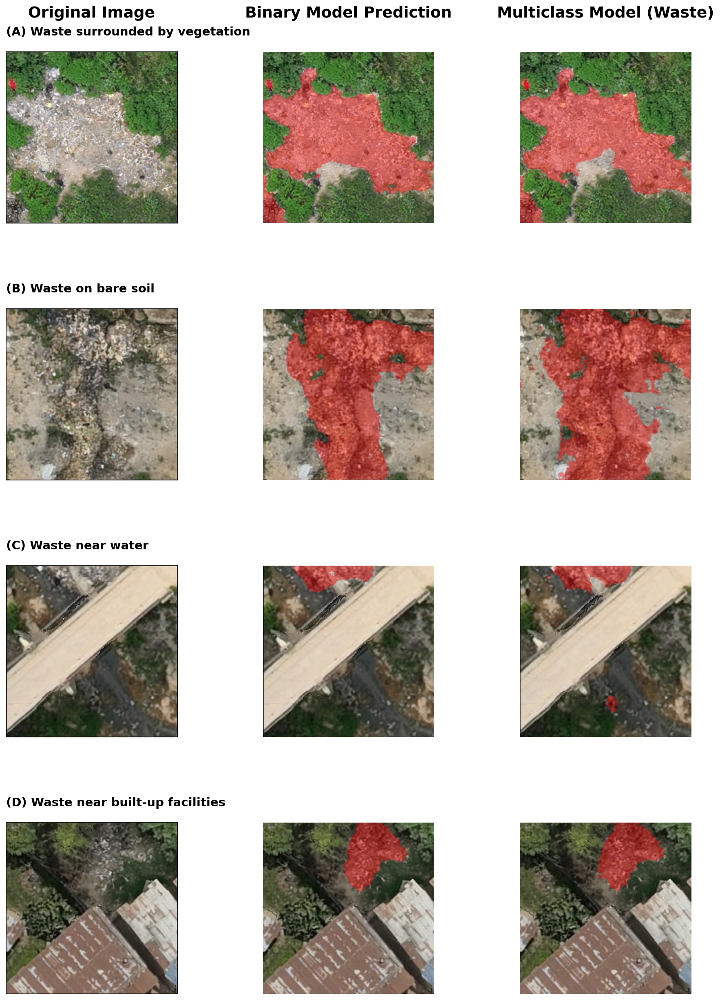

In [16]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Robust Overlay Function
def get_overlay(img, mask, color=(255, 0, 0), alpha=0.4):
    if len(mask.shape) == 3:
        mask = mask.squeeze()
    color_layer = np.zeros_like(img)
    color_layer[:] = color 
    img_colored = np.where(mask[..., None] == 1, color_layer, img)
    return cv2.addWeighted(img_colored, alpha, img, 1 - alpha, 0)

# 2. Image List Definition
image_data = [
    ("A", "clipped_image_54_tile_256_256.tif", "Waste surrounded by vegetation"),
    ("B", "clipped_image_66_tile_256_256.tif", "Waste on bare soil"),
    ("C", "clipped_image_31_tile_0_0.tif", "Waste near water"),
    ("D", "clipped_image_15_tile_512_256.tif", "Waste near built-up facilities")
]

# 3. Plotting Configuration
fig, axes = plt.subplots(len(image_data), 3, figsize=(16, 5 * len(image_data)), dpi=150)
plt.subplots_adjust(wspace=0.05, hspace=0.5) # Increased hspace for the labels

for i, (label, img_name, description) in enumerate(image_data):
    full_path = os.path.join(IMG_DIR, img_name)
    img = cv2.imread(full_path)
    if img is None: continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Preprocess
    img_resized = cv2.resize(img, (256, 256))
    img_input = np.expand_dims(img_resized / 255.0, axis=0)

    # Inference
    b_raw = binary_model.predict(img_input, verbose=0)[0]
    b_mask = (b_raw.squeeze() > 0.5).astype(np.uint8) if b_raw.shape[-1] <= 2 else np.argmax(b_raw, axis=-1).astype(np.uint8)
    m_raw = multiclass_model.predict(img_input, verbose=0)[0]
    m_mask = (np.argmax(m_raw, axis=-1) == 0).astype(np.uint8)

    # Visualization
    b_overlay = get_overlay(img_resized, b_mask, color=(255, 0, 0)) 
    m_overlay = get_overlay(img_resized, m_mask, color=(255, 0, 0)) 

    # --- Column 1: Original ---
    axes[i, 0].imshow(img_resized)
    
    # Combined Letter + Description: Uses the larger font size you liked
    # (0.0, 1.1) means start at left edge, 10% above the image
    axes[i, 0].text(0.0, 1.08, f"({label}) {description}", 
                   transform=axes[i, 0].transAxes, 
                   fontsize=14, fontweight='bold', va='bottom', ha='left')
    
    if i == 0: 
        axes[i, 0].text(0.5, 1.2, "Original Image", transform=axes[i, 0].transAxes, 
                        fontsize=18, fontweight='bold', ha='center')
    
    axes[i, 0].set_xticks([]); axes[i, 0].set_yticks([])

    # --- Column 2: Binary Model ---
    axes[i, 1].imshow(b_overlay)
    if i == 0: 
        axes[i, 1].text(0.5, 1.2, "Binary Model Prediction", transform=axes[i, 1].transAxes, 
                        fontsize=18, fontweight='bold', ha='center')
    axes[i, 1].axis('off')

    # --- Column 3: Multiclass Model ---
    axes[i, 2].imshow(m_overlay)
    if i == 0: 
        axes[i, 2].text(0.5, 1.2, "Multiclass Model (Waste)", transform=axes[i, 2].transAxes, 
                        fontsize=18, fontweight='bold', ha='center')
    axes[i, 2].axis('off')

plt.savefig("Publication_Final_Comparison.png", bbox_inches='tight', dpi=300)
plt.show()

In [17]:
1. clipped_image_54_tile_256_256.tif  - waste sorrounded by vegetation
2. clipped_image_66_tile_256_256.tif  - waste on bare soil
2. clipped_image_59_tile_256_256.tif  - waste near water
4. clipped_image_15_tile_512_256.tif  - Waste near builtup facilities

SyntaxError: invalid syntax (1374958159.py, line 1)

Size of waste pile 

In [18]:
from scipy import ndimage
import pandas as pd

pile_stats = []
threshold = 0.7 # Adjust based on your earlier observations

print("Analyzing waste pile sizes in validation set...")

for i in range(len(val_gen)):
    # Get image and ground truth from generator
    imgs, msks = val_gen[i] 
    
    # Predict using the multiclass model
    preds = multiclass_model.predict(imgs, verbose=0)
    
    for j in range(preds.shape[0]):
        # Extract the Waste Channel (Index 1)
        prob_map = preds[j, :, :, 1] 
        binary_mask = (prob_map > threshold).astype(np.uint8)
        
        # Clean the mask slightly to avoid counting single-pixel noise
        binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, np.ones((3,3)))
        
        # Identify individual piles
        labeled_mask, num_features = ndimage.label(binary_mask)
        
        # Measure size of each pile
        if num_features > 0:
            # Find the size of each labeled object
            sizes = ndimage.sum(binary_mask, labeled_mask, range(1, num_features + 1))
            
            for size in sizes:
                pile_stats.append({
                    "Image_Index": i,
                    "Filename": val_imgs[i],
                    "Pixel_Area": size,
                    "Confidence_Avg": np.mean(prob_map[binary_mask == 1])
                })

# Create the summary DataFrame
df_sizes = pd.DataFrame(pile_stats)

Analyzing waste pile sizes in validation set...


In [19]:
# Define size categories (in pixels)
def categorize_size(pixels):
    if pixels < 50: return "Small/Noise"
    if pixels < 500: return "Medium Pile"
    return "Large Accumulation"

df_sizes['Category'] = df_sizes['Pixel_Area'].apply(categorize_size)

# Summary for your report
summary = df_sizes.groupby('Category').size().reset_index(name='Count')
print(summary)

             Category  Count
0  Large Accumulation    303
1         Medium Pile    259
2         Small/Noise    369


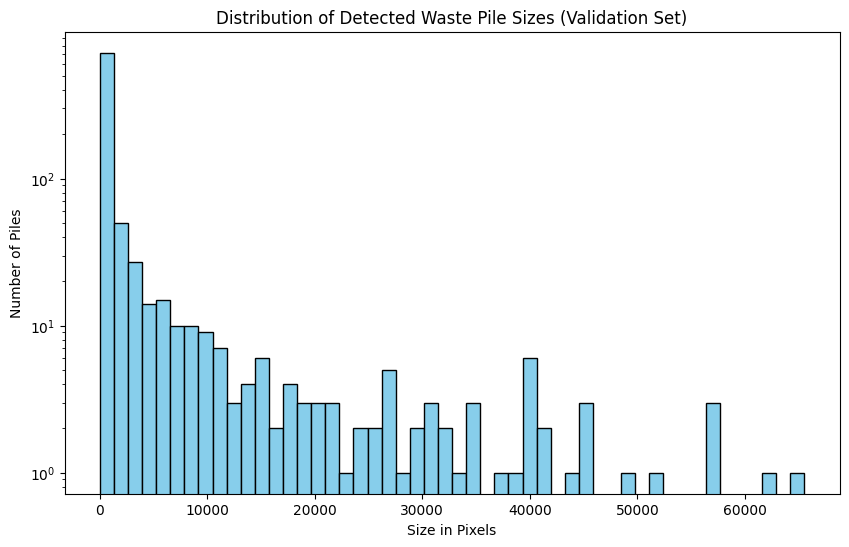

In [20]:
plt.figure(figsize=(10, 6))
plt.hist(df_sizes['Pixel_Area'], bins=50, color='skyblue', edgecolor='black')
plt.title("Distribution of Detected Waste Pile Sizes (Validation Set)")
plt.xlabel("Size in Pixels")
plt.ylabel("Number of Piles")
plt.yscale('log') # Log scale helps see small/large piles simultaneously
plt.show()

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Target Filenames ---
target_files = [
    "clipped_image_112_tile_512_0.tif",
    "clipped_image_54_tile_256_256.tif"
]

# --- 2. Find and Predict (Same logic as before) ---
found_data = []
for i in range(len(val_gen)):
    imgs, _ = val_gen[i]
    batch_start_idx = i * val_gen.batch_size
    for j in range(imgs.shape[0]):
        current_idx = batch_start_idx + j
        if current_idx < len(val_imgs):
            filename = val_imgs[current_idx]
            if filename in target_files:
                img_input = imgs[j]
                b_pred = binary_model.predict(np.expand_dims(img_input, axis=0), verbose=0)[0]
                m_pred = multiclass_model.predict(np.expand_dims(img_input, axis=0), verbose=0)[0]
                found_data.append({
                    "name": filename,
                    "img": img_input,
                    "b_prob": b_pred.squeeze(),
                    "m_prob": m_pred[:, :, correct_idx]
                })

# --- 3. Plotting the Results (Fixed Layout) ---
if not found_data:
    print("Could not find the specified files.")
else:
    # Changed: Added layout="constrained" here
    fig, axes = plt.subplots(len(found_data), 3, figsize=(18, 6 * len(found_data)), layout="constrained")
    
    if len(found_data) == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, data in enumerate(found_data):
        # Column 1: Original Image
        axes[idx, 0].imshow(data["img"])
        axes[idx, 0].set_title(f"Original: {data['name']}", fontweight='bold')
        axes[idx, 0].axis('off')
        
        # Column 2: Binary Model Probability
        im1 = axes[idx, 1].imshow(data["b_prob"], cmap='magma', vmin=0, vmax=1)
        axes[idx, 1].set_title("Binary Model Confidence", fontsize=12)
        axes[idx, 1].axis('off')
        fig.colorbar(im1, ax=axes[idx, 1], shrink=0.8) # shrink makes it look cleaner
        
        # Column 3: Multiclass Model Probability
        im2 = axes[idx, 2].imshow(data["m_prob"], cmap='magma', vmin=0, vmax=1)
        axes[idx, 2].set_title("Multiclass Model Confidence", fontsize=12)
        axes[idx, 2].axis('off')
        fig.colorbar(im2, ax=axes[idx, 2], shrink=0.8)

    # Removed: plt.tight_layout() is no longer needed with layout="constrained"
    plt.show()

Could not find the specified files.


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import string

# --- 1. Settings ---
RESOLUTION = 0.038  # meters per pixel (3.8 cm)
pixel_area = RESOLUTION ** 2  # m² per pixel

target_files = [
    "clipped_image_112_tile_512_0.tif",
    "clipped_image_54_tile_256_256.tif"
]

# --- 2. Find, Predict, and Measure ---
found_data = []

for i in range(len(val_gen)):
    imgs, msks = val_gen[i]
    batch_start_idx = i * val_gen.batch_size

    for j in range(imgs.shape[0]):
        current_idx = batch_start_idx + j

        if current_idx < len(val_imgs) and val_imgs[current_idx] in target_files:
            img_input = imgs[j]
            gt_mask = (msks[j, ..., 0] == 1).astype(np.uint8)

            # Waste area calculation
            pixel_count = np.sum(gt_mask)
            area_m2 = pixel_count * pixel_area

            # Model inference
            b_probs = binary_model.predict(
                np.expand_dims(img_input, axis=0), verbose=0
            )[0].squeeze()

            m_probs = multiclass_model.predict(
                np.expand_dims(img_input, axis=0), verbose=0
            )[0][:, :, correct_idx]

            found_data.append({
                "name": val_imgs[current_idx],
                "img": img_input,
                "px_size": pixel_count,
                "m2_size": area_m2,
                "b_prob": b_probs,
                "m_prob": m_probs
            })

# --- 3. Sort by target_files order ---
order_map = {name: i for i, name in enumerate(target_files)}
found_data.sort(key=lambda x: order_map.get(x["name"], 999))

# --- 4. Plotting ---
if not found_data:
    print("Files not found.")
else:
    fig, axes = plt.subplots(
        len(found_data), 3,
        figsize=(18, 6 * len(found_data)),
        layout="constrained"
    )

    if len(found_data) == 1:
        axes = np.expand_dims(axes, axis=0)

    labels = string.ascii_uppercase 

    for idx, data in enumerate(found_data):
        letter = labels[idx]

        # Column 1: Original Image + Flowing Title
        axes[idx, 0].imshow(data["img"])
        title_text = f"({letter}) Waste pile of {data['px_size']} pixels covering {data['m2_size']:.2f} m²"
        axes[idx, 0].set_title(title_text, fontsize=14, fontweight='bold', pad=20)
        axes[idx, 0].axis('off')

        # Column 2: Binary Model Confidence
        im1 = axes[idx, 1].imshow(data["b_prob"], cmap='jet', vmin=0, vmax=1)
        axes[idx, 1].set_title("Binary Model Confidence", fontsize=12)
        axes[idx, 1].axis('off')
        fig.colorbar(im1, ax=axes[idx, 1], shrink=0.7)

        # Column 3: Multiclass Model Confidence
        im2 = axes[idx, 2].imshow(data["m_prob"], cmap='jet', vmin=0, vmax=1)
        axes[idx, 2].set_title("Multiclass Model Confidence", fontsize=12)
        axes[idx, 2].axis('off')
        fig.colorbar(im2, ax=axes[idx, 2], shrink=0.7)

    plt.show()

Files not found.


In [23]:
from scipy import ndimage
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

for i in range(len(val_gen)):
    # 1. Get Image, Ground Truth (GT), and Prediction
    imgs, msks = val_gen[i]
    preds = multiclass_model.predict(imgs, verbose=0)
    
    for j in range(preds.shape[0]):
        gt_mask = (msks[j, ..., 0] == 1).astype(np.uint8) # Adjust index if needed
        pred_mask = (np.argmax(preds[j], axis=-1) == 1).astype(np.uint8)
        
        # 2. Identify individual real piles in Ground Truth
        labeled_gt, num_piles = ndimage.label(gt_mask)
        
        for pile_id in range(1, num_piles + 1):
            single_pile_gt = (labeled_gt == pile_id).astype(np.uint8)
            pile_size = np.sum(single_pile_gt)
            
            # 3. Check for overlap (Detection)
            # Intersection of this specific real pile and the whole prediction
            intersection = np.logical_and(single_pile_gt, pred_mask).sum()
            detected = 1 if (intersection / pile_size) > 0.3 else 0 # 30% overlap rule
            
            results.append({
                "Pile_Size": pile_size,
                "Detected": detected
            })

df_perf = pd.DataFrame(results)

In [24]:
# Create size bins
bins = [0, 100, 500, 2000, 10000]
labels = ['Tiny (<100)', 'Small (100-500)', 'Medium (500-2k)', 'Large (>2k)']
df_perf['Size_Category'] = pd.cut(df_perf['Pile_Size'], bins=bins, labels=labels)

# Calculate Recall per Size
size_summary = df_perf.groupby('Size_Category')['Detected'].mean().reset_index()
size_summary.columns = ['Size Category', 'Recall (Detection Rate)']

print(size_summary)

     Size Category  Recall (Detection Rate)
0      Tiny (<100)                 0.157895
1  Small (100-500)                 0.323529
2  Medium (500-2k)                 0.200000
3      Large (>2k)                 0.000000


C:\Users\Peter\AppData\Local\Temp\ipykernel_34488\1705434357.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  size_summary = df_perf.groupby('Size_Category')['Detected'].mean().reset_index()


Analyzing 26 validation batches...


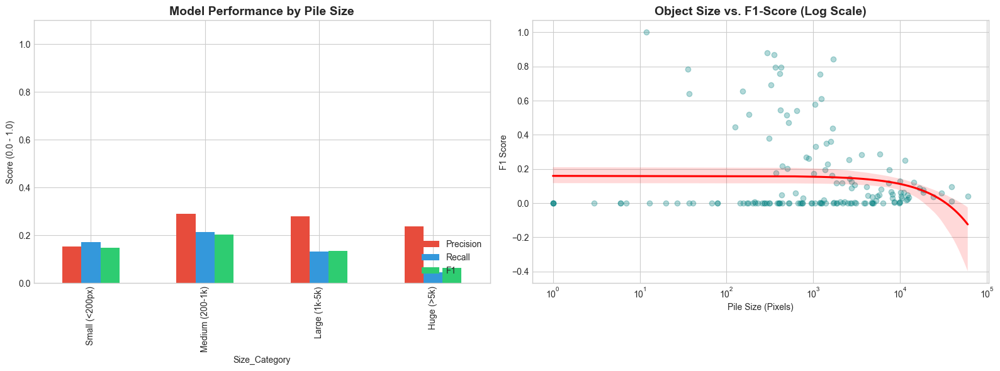


--- PERFORMANCE SUMMARY BY SIZE ---
     Size_Category  Precision    Recall        F1
0   Small (<200px)   0.154034  0.171763  0.149653
1  Medium (200-1k)   0.289305  0.213731  0.202803
2    Large (1k-5k)   0.280513  0.133268  0.135662
3       Huge (>5k)   0.239086  0.045186  0.064194


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import ndimage
from sklearn.metrics import precision_score, recall_score, f1_score

# --- 1. Configuration ---
WASTE_CHANNEL = 1  # Your confirmed waste index
CONF_THRESHOLD = 0.5
SIZE_BINS = [0, 200, 1000, 5000, np.inf]
BIN_LABELS = ['Small (<200px)', 'Medium (200-1k)', 'Large (1k-5k)', 'Huge (>5k)']

all_pile_results = []

print(f"Analyzing {len(val_gen)} validation batches...")

# --- 2. Object-Based Extraction Loop ---
for i in range(len(val_gen)):
    imgs, msks = val_gen[i]
    preds = multiclass_model.predict(imgs, verbose=0)
    
    for j in range(preds.shape[0]):
        # Extract Ground Truth and Prediction masks
        # Assuming MASK_DIR images are (H, W, 1) and waste is value 1
        gt_mask = (msks[j, ..., 0] == 1).astype(np.uint8)
        
        # Multiclass prediction logic
        pred_probs = preds[j, :, :, WASTE_CHANNEL]
        pred_mask = (np.argmax(preds[j], axis=-1) == WASTE_CHANNEL).astype(np.uint8)
        
        # Label individual piles in Ground Truth
        labeled_gt, num_piles = ndimage.label(gt_mask)
        
        for pile_id in range(1, num_piles + 1):
            # Create a mask for just this specific real pile
            single_pile_gt = (labeled_gt == pile_id).astype(np.uint8)
            pile_size = np.sum(single_pile_gt)
            
            # Calculate pixel-wise metrics for THIS specific pile area
            # We look at the prediction quality within the bounding box of the real pile
            y, x = np.where(single_pile_gt)
            y_min, y_max, x_min, x_max = y.min(), y.max(), x.min(), x.max()
            
            # Crop to the pile area (with a small 2px buffer) for local evaluation
            roi_gt = gt_mask[y_min:y_max+1, x_min:x_max+1].flatten()
            roi_pred = pred_mask[y_min:y_max+1, x_min:x_max+1].flatten()
            
            # Metric calculation for this object
            p = precision_score(roi_gt, roi_pred, zero_division=0)
            r = recall_score(roi_gt, roi_pred, zero_division=0)
            f1 = f1_score(roi_gt, roi_pred, zero_division=0)
            
            all_pile_results.append({
                "Size_Pixels": pile_size,
                "Precision": p,
                "Recall": r,
                "F1": f1,
                "Detected": 1 if r > 0.3 else 0  # Detected if 30% of the pile is found
            })

# --- 3. Data Processing ---
df_stats = pd.DataFrame(all_pile_results)
df_stats['Size_Category'] = pd.cut(df_stats['Size_Pixels'], bins=SIZE_BINS, labels=BIN_LABELS)

# Calculate averages per size bin
performance_summary = df_stats.groupby('Size_Category', observed=True)[['Precision', 'Recall', 'F1']].mean().reset_index()

# --- 4. Visualization ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Graph 1: Performance Metrics vs Size
performance_summary.set_index('Size_Category').plot(kind='bar', ax=ax1, color=['#e74c3c', '#3498db', '#2ecc71'])
ax1.set_title("Model Performance by Pile Size", fontsize=14, fontweight='bold')
ax1.set_ylabel("Score (0.0 - 1.0)")
ax1.set_ylim(0, 1.1)
ax1.legend(loc='lower right')

# Graph 2: Scatter Plot of Size vs F1 Score
sns.regplot(x='Size_Pixels', y='F1', data=df_stats, ax=ax2, 
            scatter_kws={'alpha':0.3, 'color':'teal'}, line_kws={'color':'red'})
ax2.set_xscale('log') # Log scale helps view small and large piles
ax2.set_title("Object Size vs. F1-Score (Log Scale)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Pile Size (Pixels)")
ax2.set_ylabel("F1 Score")

plt.tight_layout()
plt.show()

# --- 5. Export to Excel ---
#performance_summary.to_excel("Waste_Performance_By_Size.xlsx", index=False)
print("\n--- PERFORMANCE SUMMARY BY SIZE ---")
print(performance_summary.to_string())

Index Discovery: 'Waste' identified at Channel Index 0


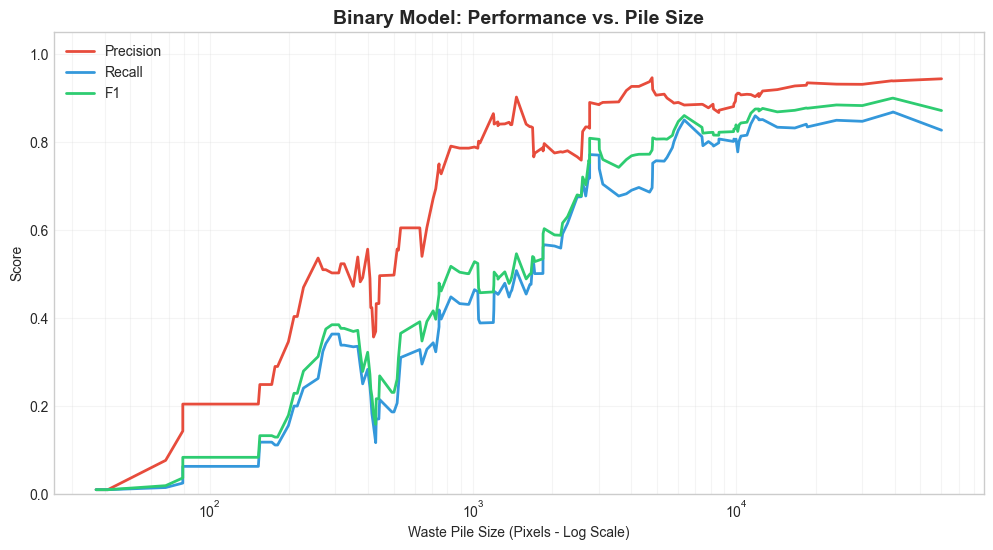

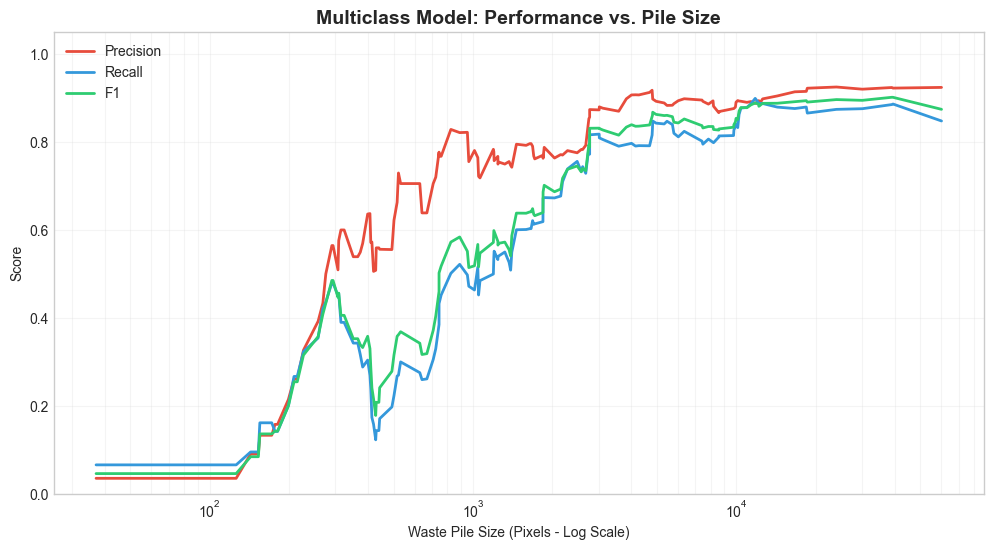

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import ndimage
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. AUTOMATIC INDEX DISCOVERY
def detect_waste_index(model, gen, num_samples=10):
    """Detects which channel matches the Waste labels by calculating IoU."""
    ious = []
    for i in range(min(num_samples, len(gen))):
        imgs, msks = gen[i]
        preds = model.predict(imgs, verbose=0)
        for j in range(preds.shape[0]):
            gt = (msks[j, ..., 0] == 1).astype(np.uint8)
            channel_ious = []
            for c in range(preds.shape[-1]):
                pred_c = (np.argmax(preds[j], axis=-1) == c).astype(np.uint8)
                inter = np.logical_and(gt, pred_c).sum()
                union = np.logical_or(gt, pred_c).sum()
                channel_ious.append(inter / (union + 1e-6))
            ious.append(channel_ious)
    
    best_idx = np.argmax(np.mean(ious, axis=0))
    print(f"Index Discovery: 'Waste' identified at Channel Index {best_idx}")
    return best_idx

# 2. OBJECT-BASED METRIC EXTRACTION
def get_performance_data(model, gen, is_multiclass=True, waste_idx=1):
    data = []
    for i in range(len(gen)):
        imgs, msks = gen[i]
        preds = model.predict(imgs, verbose=0)
        for j in range(preds.shape[0]):
            gt = (msks[j, ..., 0] == 1).astype(np.uint8)
            if is_multiclass:
                pred = (np.argmax(preds[j], axis=-1) == waste_idx).astype(np.uint8)
            else:
                pred = (preds[j].squeeze() > 0.5).astype(np.uint8)
            
            labeled_gt, num_piles = ndimage.label(gt)
            for p_id in range(1, num_piles + 1):
                pile_mask = (labeled_gt == p_id)
                size = np.sum(pile_mask)
                
                # Local evaluation within the pile's bounding box
                y, x = np.where(pile_mask)
                roi_gt = gt[y.min():y.max()+1, x.min():x.max()+1].flatten()
                roi_pred = pred[y.min():y.max()+1, x.min():x.max()+1].flatten()
                
                data.append({
                    "Size": size,
                    "Precision": precision_score(roi_gt, roi_pred, zero_division=0),
                    "Recall": recall_score(roi_gt, roi_pred, zero_division=0),
                    "F1": f1_score(roi_gt, roi_pred, zero_division=0)
                })
    return pd.DataFrame(data).sort_values('Size')

# --- RUN ANALYSIS ---
# Detect correct index for Multiclass
correct_idx = detect_waste_index(multiclass_model, val_gen)

# Gather data for both models
df_bin = get_performance_data(binary_model, val_gen, is_multiclass=False)
df_multi = get_performance_data(multiclass_model, val_gen, is_multiclass=True, waste_idx=correct_idx)

# 3. PLOTTING TRENDS (Smoothing applied for readability)
def plot_trends(df, title):
    plt.figure(figsize=(12, 6))
    # Using a rolling mean to show the 'Line' change without the noise of individual dots
    window = 15 
    for metric, color in zip(['Precision', 'Recall', 'F1'], ['#e74c3c', '#3498db', '#2ecc71']):
        # Smooth the data using a rolling average across sorted sizes
        smoothed = df.rolling(window=window, on='Size').mean()
        plt.plot(smoothed['Size'], smoothed[metric], label=metric, color=color, linewidth=2)
    
    plt.xscale('log') # Log scale is essential for vast size ranges (e.g. 10px to 10,000px)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel("Waste Pile Size (Pixels - Log Scale)")
    plt.ylabel("Score")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(True, which="both", ls="-", alpha=0.2)

plot_trends(df_bin, "Binary Model: Performance vs. Pile Size")
plot_trends(df_multi, "Multiclass Model: Performance vs. Pile Size")
plt.show()

In [116]:
print(df_bin)

      Size  Precision    Recall        F1
188      1   0.000000  0.000000  0.000000
21       1   0.000000  0.000000  0.000000
135      1   0.000000  0.000000  0.000000
143      1   0.000000  0.000000  0.000000
148      1   0.000000  0.000000  0.000000
..     ...        ...       ...       ...
146  29571   0.978079  0.793649  0.876265
165  31201   0.952545  0.957918  0.955224
157  33361   0.971236  0.927101  0.948655
138  37136   0.942249  0.910256  0.925976
49   41440   0.939940  0.679543  0.788807

[194 rows x 4 columns]


In [27]:
from scipy import ndimage

# Define the small range
SMALL_MIN = 1000
SMALL_MAX = 2000

small_pile_filenames = []

print(f"Scanning for images where the largest pile is between {SMALL_MIN} and {SMALL_MAX} pixels...")

for i in range(len(val_gen)):
    imgs, msks = val_gen[i]
    for j in range(imgs.shape[0]):
        # Get ground truth for this specific image
        gt = (msks[j, ..., 0] == 1).astype(np.uint8)
        
        # Label the piles
        labeled, num_piles = ndimage.label(gt)
        
        if num_piles > 0:
            # Calculate sizes of all piles in this image
            sizes = [np.sum(labeled == p_id) for p_id in range(1, num_piles + 1)]
            max_pile_in_image = max(sizes)
            
            # Check if it fits the "Small" criteria
            if SMALL_MIN <= max_pile_in_image <= SMALL_MAX:
                # Calculate index to match with val_imgs list
                img_idx = i * val_gen.batch_size + j
                if img_idx < len(val_imgs):
                    small_pile_filenames.append(val_imgs[img_idx])

# Remove duplicates and sort
small_pile_filenames = sorted(list(set(small_pile_filenames)))

print(f"\nFound {len(small_pile_filenames)} images with small waste piles:")
print("-" * 30)
for name in small_pile_filenames:
    print(name)

Scanning for images where the largest pile is between 1000 and 2000 pixels...

Found 11 images with small waste piles:
------------------------------
clipped_image_113_tile_0_0.tif
clipped_image_22_tile_0_256.tif
clipped_image_27_tile_0_256.tif
clipped_image_30_tile_0_0.tif
clipped_image_53_tile_512_0.tif
clipped_image_5_tile_512_0.tif
clipped_image_64_tile_256_0.tif
clipped_image_66_tile_256_512.tif
clipped_image_75_tile_512_256.tif
clipped_image_8_tile_0_512.tif
clipped_image_94_tile_256_512.tif


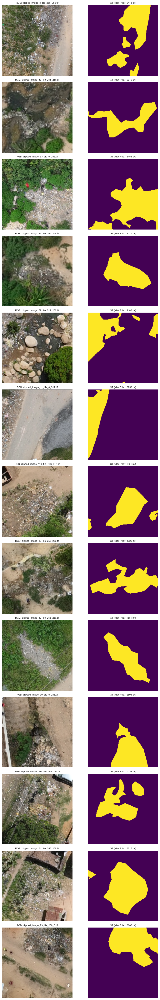

Plotted 13 images.


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# --- 1. Identify and Collect Data for All Matches ---
matches = []
SMALL_MIN = 10000
SMALL_MAX = 20000

for i in range(len(val_gen)):
    imgs, msks = val_gen[i]
    for j in range(imgs.shape[0]):
        gt = (msks[j, ..., 0] == 1).astype(np.uint8)
        labeled, num_piles = ndimage.label(gt)
        
        if num_piles > 0:
            sizes = [np.sum(labeled == p_id) for p_id in range(1, num_piles + 1)]
            max_p = max(sizes)
            
            if SMALL_MIN <= max_p <= SMALL_MAX:
                img_idx = i * val_gen.batch_size + j
                if img_idx < len(val_imgs):
                    matches.append({
                        "img": imgs[j],
                        "mask": gt,
                        "name": val_imgs[img_idx],
                        "size": max_p
                    })

# --- 2. Dynamic Grid Plotting ---
num_matches = len(matches)
if num_matches == 0:
    print("No images found in that size range.")
else:
    # We create 2 columns (Image and Mask) for every match
    # We'll stack them so you see 2 images per row for a cleaner look, or 3 sets of 2.
    cols = 2 
    rows = num_matches
    
    fig, axes = plt.subplots(rows, cols, figsize=(10, 4 * rows))
    
    # Handle the case where there is only 1 match (axes is not a 2D array)
    if rows == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, data in enumerate(matches):
        # Original Image
        axes[idx, 0].imshow(data["img"])
        axes[idx, 0].set_title(f"RGB: {data['name']}", fontsize=9)
        axes[idx, 0].axis('off')
        
        # Ground Truth Mask
        # Using 'viridis' or 'jet' helps the 1000px pile stand out
        axes[idx, 1].imshow(data["mask"], cmap='viridis') 
        axes[idx, 1].set_title(f"GT (Max Pile: {data['size']} px)", fontsize=9)
        axes[idx, 1].axis('off')

    plt.tight_layout()
    plt.show()

print(f"Plotted {num_matches} images.")

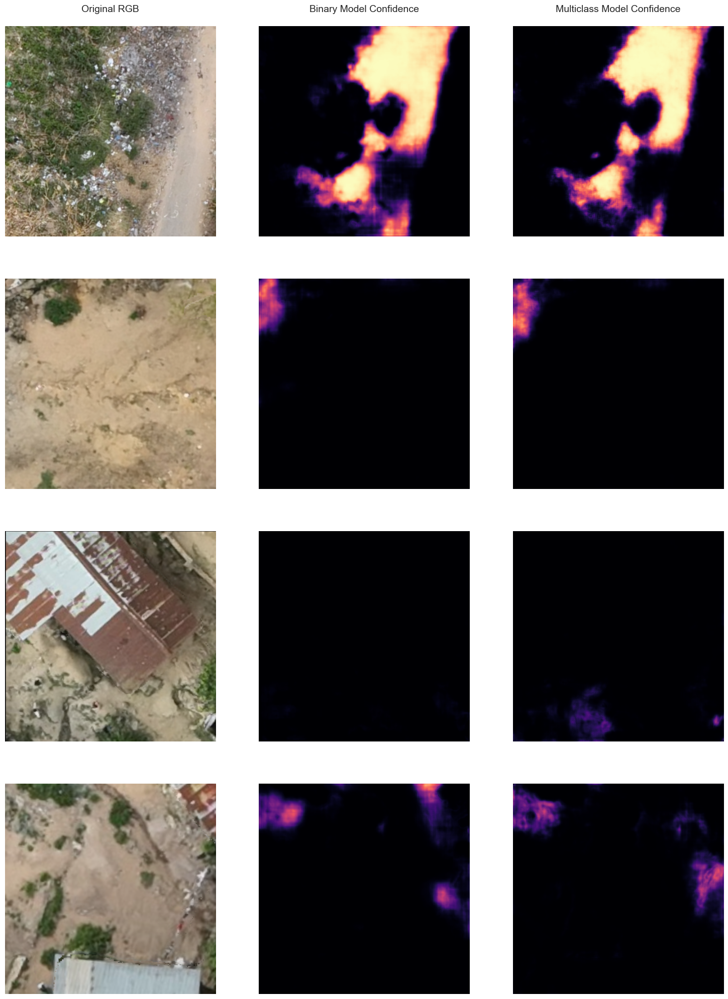

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

# --- 1. Settings ---
# WASTE_IDX should be the one identified by detect_waste_index (e.g., 0 or 1)
WASTE_IDX = correct_idx 
categories = {
    "Small Pile": (10, 200),
    "Medium Pile": (201, 1000),
    "Large Pile": (1001, 5000),
    "Huge Pile": (5001, 65536) # Up to full 256x256
}

selected_samples = {}

# --- 2. Systematic Search for Full-Frame Samples ---
for i in range(len(val_gen)):
    imgs, msks = val_gen[i]
    for j in range(imgs.shape[0]):
        gt = (msks[j, ..., 0] == 1).astype(np.uint8)
        labeled, num_piles = ndimage.label(gt)
        
        # Check all piles in this specific image
        if num_piles > 0:
            sizes = [np.sum(labeled == p_id) for p_id in range(1, num_piles + 1)]
            max_size = max(sizes)
            
            for cat_name, (low, high) in categories.items():
                if low <= max_size <= high and cat_name not in selected_samples:
                    selected_samples[cat_name] = {
                        "img": imgs[j],
                        "gt": gt,
                        "size": max_size
                    }
    if len(selected_samples) == 4: break

# --- 3. Plotting Full Frames ---
fig, axes = plt.subplots(4, 3, figsize=(15, 20), dpi=100)

for idx, (cat_name, data) in enumerate(selected_samples.items()):
    img_input = np.expand_dims(data["img"], axis=0)
    
    # Model Predictions
    b_raw = binary_model.predict(img_input, verbose=0)[0]
    m_raw = multiclass_model.predict(img_input, verbose=0)[0]
    
    # Extract Probabilities (Full 256x256)
    b_probs = b_raw.squeeze()
    m_probs = m_raw[:, :, WASTE_IDX]
    
    # Col 1: Original RGB
    axes[idx, 0].imshow(data["img"])
    axes[idx, 0].set_ylabel(f"{cat_name}\nMax Pile: {data['size']}px", fontsize=12, fontweight='bold')
    if idx == 0: axes[idx, 0].set_title("Original RGB", pad=20, fontsize=14)
    axes[idx, 0].axis('off')
    
    # Col 2: Binary Probability Heatmap
    im2 = axes[idx, 1].imshow(b_probs, cmap='magma', vmin=0, vmax=1)
    if idx == 0: axes[idx, 1].set_title("Binary Model Confidence", pad=20, fontsize=14)
    axes[idx, 1].axis('off')
    
    # Col 3: Multiclass Probability Heatmap
    im3 = axes[idx, 2].imshow(m_probs, cmap='magma', vmin=0, vmax=1)
    if idx == 0: axes[idx, 2].set_title("Multiclass Model Confidence", pad=20, fontsize=14)
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.subplots_adjust(wspace=0.1, hspace=0.2)
plt.show()

In [30]:
m_mask

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

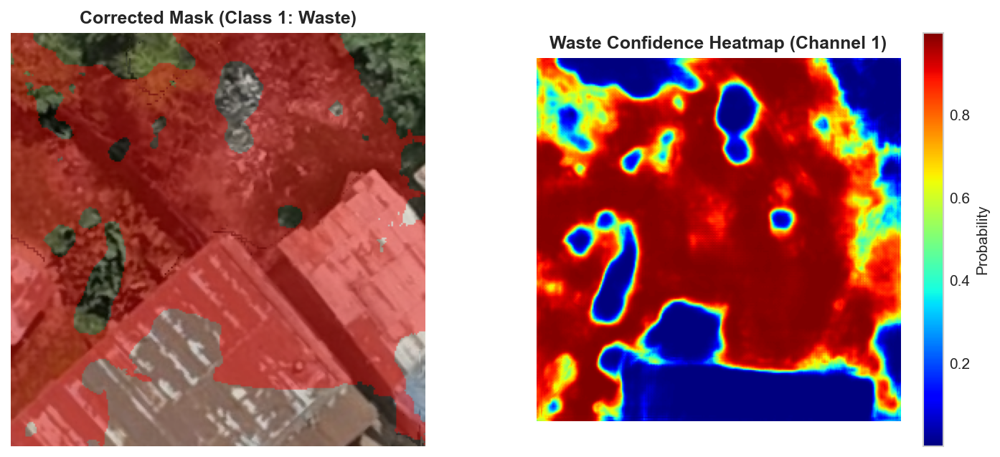

In [31]:
# Assuming m_raw shape is (256, 256, num_classes)
# If index 1 is Waste, we extract channel 1
waste_probs = m_raw[:, :, 1] 

# Correct the mask to use Index 1
m_mask_corrected = (np.argmax(m_raw, axis=-1) == 1).astype(np.uint8)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=150)

# A. The Hard Mask (Final Decision)
axes[0].imshow(get_overlay(img_resized, m_mask_corrected))
axes[0].set_title("Corrected Mask (Class 1: Waste)", fontweight='bold')
axes[0].axis('off')

# B. The Probability Map (Confidence)
# 'jet' or 'viridis' maps show high probability as red/yellow
im = axes[1].imshow(waste_probs, cmap='jet')
axes[1].set_title("Waste Confidence Heatmap (Channel 1)", fontweight='bold')
fig.colorbar(im, ax=axes[1], label='Probability')
axes[1].axis('off')

plt.show()

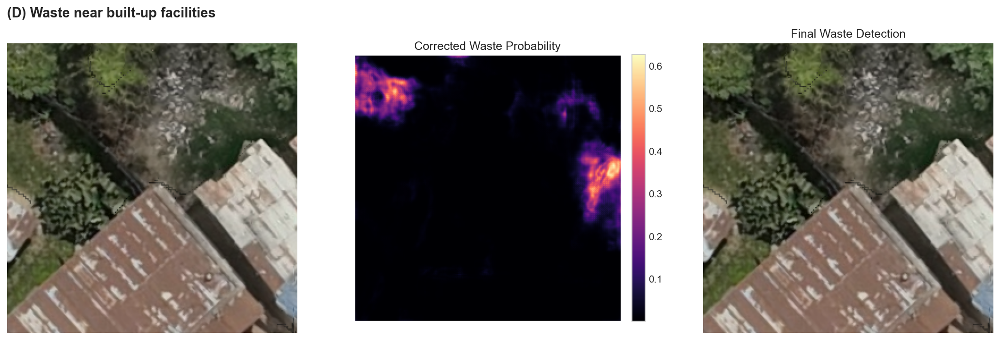

In [32]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# --- 1. Settings ---
# If Channel 1 was the "Opposite", Channel 0 is likely the Waste
WASTE_CHANNEL = 0  
THRESHOLD = 0.6 

# --- 2. Inference & Inversion Check ---
m_raw = multiclass_model.predict(img_input, verbose=0)[0]

# We take the probability of the actual waste channel
m_probs = m_raw[:, :, WASTE_CHANNEL]

# 3. Create the Mask
m_mask = (m_probs > THRESHOLD).astype(np.uint8)

# --- 4. Cleaning the Mask (Morphology) ---
# This removes small false-positive "dots" and fills small holes in the pile
kernel = np.ones((3,3), np.uint8)
m_mask_cleaned = cv2.morphologyEx(m_mask, cv2.MORPH_OPEN, kernel) # Removes noise

# --- 5. Plotting ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=150)

# Col 1: Original
axes[0].imshow(img_resized)
axes[0].text(0.0, 1.08, f"({label}) {description}", transform=axes[0].transAxes, 
            fontsize=14, fontweight='bold', va='bottom', ha='left')
axes[0].axis('off')

# Col 2: The Inverted Heatmap 
# This should now show the WASTE as bright/hot colors
im = axes[1].imshow(m_probs, cmap='magma')
axes[1].set_title("Corrected Waste Probability", fontsize=12)
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].axis('off')

# Col 3: Cleaned Overlay
m_overlay = get_overlay(img_resized, m_mask_cleaned, color=(0, 255, 0), alpha=0.5)
axes[2].imshow(m_overlay)
axes[2].set_title("Final Waste Detection", fontsize=12)
axes[2].axis('off')

plt.show()

In [ ]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Image List
image_data = [
    ("clipped_image_54_tile_256_256.tif", "Waste surrounded by vegetation"),
    ("clipped_image_66_tile_256_256.tif", "Waste on bare soil"),
    ("clipped_image_59_tile_256_256.tif", "Waste near water"),
    ("clipped_image_15_tile_512_256.tif", "Waste near built-up facilities")
]

def get_overlay(img, mask, color=(255, 0, 0), alpha=0.4):
    if len(mask.shape) == 3: mask = mask.squeeze()
    color_layer = np.zeros_like(img)
    color_layer[:] = color 
    img_colored = np.where(mask[..., None] == 1, color_layer, img)
    return cv2.addWeighted(img_colored, alpha, img, 1 - alpha, 0)

# 2. Plotting Configuration
fig, axes = plt.subplots(len(image_data), 3, figsize=(16, 4.5 * len(image_data)), dpi=150)

# ADJUST MARGINS: Increase 'left' and decrease 'right' to move columns away from edges
# wspace=0.05 keeps images close to each other, left/right creates the outer padding
plt.subplots_adjust(left=0.15, right=0.85, wspace=0.05, hspace=0.2) 

row_letters = ['(a)', '(b)', '(c)', '(d)']

for i, (img_name, caption) in enumerate(image_data):
    full_path = os.path.join(IMG_DIR, img_name)
    img = cv2.imread(full_path)
    if img is None: continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    img_resized = cv2.resize(img, (256, 256))
    img_input = np.expand_dims(img_resized / 255.0, axis=0)

    # Inference
    b_raw = binary_model.predict(img_input, verbose=0)[0]
    b_mask = (b_raw.squeeze() > 0.5).astype(np.uint8) if b_raw.shape[-1] <= 2 else np.argmax(b_raw, axis=-1).astype(np.uint8)

    m_raw = multiclass_model.predict(img_input, verbose=0)[0]
    m_mask = (np.argmax(m_raw, axis=-1) == 0).astype(np.uint8)

    # Visualization
    b_overlay = get_overlay(img_resized, b_mask, color=(255, 0, 0))
    m_overlay = get_overlay(img_resized, m_mask, color=(255, 0, 0))

    # --- ROW CAPTIONS (Black Text) ---
    axes[i, 0].text(0, -12, f"{row_letters[i]} {caption}", fontsize=11, fontweight='bold', color='black')

    # --- COLUMN HEADERS (Top Row Only, Black Text) ---
    if i == 0:
        axes[i, 0].set_title("Original Image", fontsize=12, pad=35, color='black', fontweight='bold')
        axes[i, 1].set_title("Binary Prediction", fontsize=12, pad=35, color='black', fontweight='bold')
        axes[i, 2].set_title("Multiclass-based Prediction", fontsize=12, pad=35, color='black', fontweight='bold')

    # --- RENDER ---
    axes[i, 0].imshow(img_resized)
    axes[i, 1].imshow(b_overlay)
    axes[i, 2].imshow(m_overlay)

    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values(): spine.set_visible(False)

# Using bbox_inches='tight' ensures that even with the new margins, nothing is cut off
plt.savefig("Waste_Analysis_Centered_Grid.png", bbox_inches='tight', dpi=300)
plt.show()

Comparisons

In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import f1_score, precision_score, recall_score

# 1. Configuration
NATIVE_RES_CM = 3.811
MAX_RES_CM = 50.0    # How far out you want to test
NUM_STEPS = 5       # Narrow/uniform intervals

# Generate uniform resolutions from native to coarse
target_res_cm = np.linspace(NATIVE_RES_CM, MAX_RES_CM, NUM_STEPS)
# factor = native_res / target_res
res_factors = [NATIVE_RES_CM / r for r in target_res_cm]

results_uniform = []
INTERNAL_IDX = LABEL_MAP[1] 

print(f"Running study from {NATIVE_RES_CM}cm to {MAX_RES_CM}cm...")

for i, f in enumerate(res_factors):
    y_true_all = []
    y_pred_all = []
    current_cm = target_res_cm[i]
    
    print(f"Step {i+1}/{NUM_STEPS}: {current_cm:.2f} cm/px", end="... ")

    # We iterate by index to ensure proper batch handling
    for j in range(len(val_gen)):
        batch_x, batch_y = val_gen[j]
        
        # Ensure batch_x is 4D (Batch, H, W, C)
        batch_x = tf.convert_to_tensor(batch_x)
        
        # Calculate new dimensions
        h_low = max(1, int(256 * f))
        w_low = max(1, int(256 * f))
        
        # 2. Simulate resolution drop
        x_low = tf.image.resize(batch_x, (h_low, w_low), method="bilinear")
        x_resampled = tf.image.resize(x_low, (256, 256), method="bilinear")

        # 3. Inference
        preds = model.predict(x_resampled, verbose=0)
        pred_classes = np.argmax(preds, axis=-1)
        true_classes = np.argmax(batch_y, axis=-1)

        y_true_all.append((true_classes == INTERNAL_IDX).astype(np.uint8).ravel())
        y_pred_all.append((pred_classes == INTERNAL_IDX).astype(np.uint8).ravel())

    yt = np.concatenate(y_true_all)
    yp = np.concatenate(y_pred_all)
    
    results_uniform.append({
        "res_cm": current_cm,
        "f1": f1_score(yt, yp, zero_division=0),
        "precision": precision_score(yt, yp, zero_division=0),
        "recall": recall_score(yt, yp, zero_division=0)
    })
    print(f"F1: {results_uniform[-1]['f1']:.3f}")



Running study from 3.811cm to 50.0cm...
Step 1/5: 3.81 cm/px... F1: 0.851
Step 2/5: 15.36 cm/px... F1: 0.326
Step 3/5: 26.91 cm/px... F1: 0.199
Step 4/5: 38.45 cm/px... F1: 0.209
Step 5/5: 50.00 cm/px... F1: 0.211


Starting Resolution Study...
Points < 15cm: 15 | Points > 15cm: 20
Step 1/35: Testing 3.81 cm/px... F1: 0.851
Step 2/35: Testing 4.61 cm/px... F1: 0.838
Step 3/35: Testing 5.41 cm/px... F1: 0.830
Step 4/35: Testing 6.21 cm/px... F1: 0.818
Step 5/35: Testing 7.01 cm/px... F1: 0.794
Step 6/35: Testing 7.81 cm/px... F1: 0.769
Step 7/35: Testing 8.61 cm/px... F1: 0.744
Step 8/35: Testing 9.41 cm/px... F1: 0.715
Step 9/35: Testing 10.20 cm/px... F1: 0.674
Step 10/35: Testing 11.00 cm/px... F1: 0.631
Step 11/35: Testing 11.80 cm/px... F1: 0.570
Step 12/35: Testing 12.60 cm/px... F1: 0.517
Step 13/35: Testing 13.40 cm/px... F1: 0.455
Step 14/35: Testing 14.20 cm/px... F1: 0.388
Step 15/35: Testing 15.00 cm/px... F1: 0.337
Step 16/35: Testing 16.75 cm/px... F1: 0.253
Step 17/35: Testing 18.50 cm/px... F1: 0.217
Step 18/35: Testing 20.25 cm/px... F1: 0.200
Step 19/35: Testing 22.00 cm/px... F1: 0.196
Step 20/35: Testing 23.75 cm/px... F1: 0.191
Step 21/35: Testing 25.50 cm/px... F1: 0.187
Step 

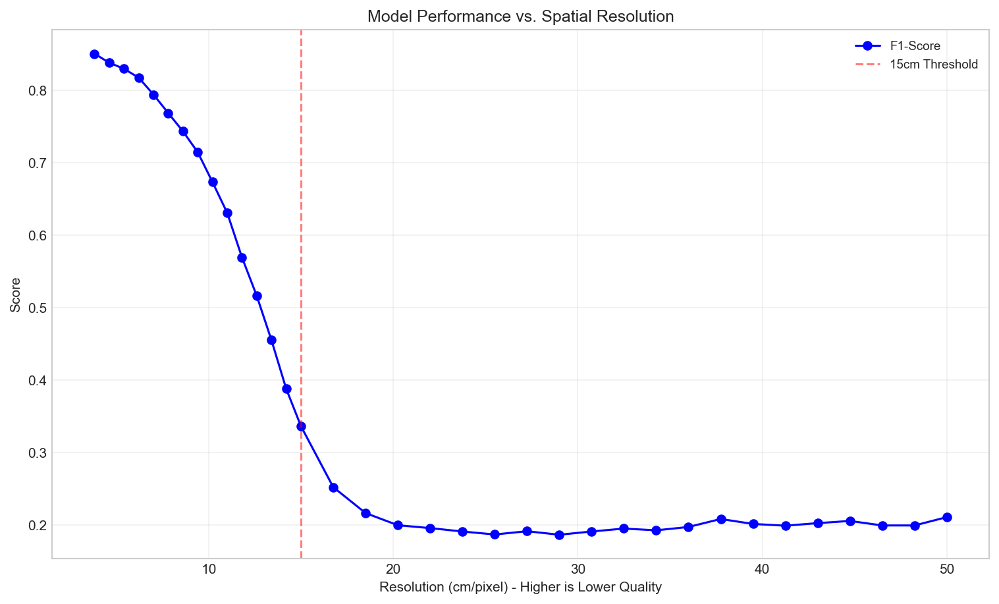


--- Summary Table ---
   res_cm       f1  precision   recall
 3.811000 0.850747   0.852530 0.848971
 4.610214 0.838271   0.869783 0.808962
 5.409429 0.829961   0.870550 0.792989
 6.208643 0.817622   0.878643 0.764527
 7.007857 0.794368   0.886308 0.719710
 7.807071 0.768866   0.893467 0.674765
 8.606286 0.743615   0.896666 0.635194
 9.405500 0.714841   0.894293 0.595372
10.204714 0.673681   0.888766 0.542415
11.003929 0.631092   0.882925 0.491036
11.803143 0.569684   0.867486 0.424095
12.602357 0.516773   0.858507 0.369637
13.401571 0.455443   0.858079 0.309987
14.200786 0.388338   0.825566 0.253880
15.000000 0.336754   0.810384 0.212537
16.750000 0.252600   0.760243 0.151463
18.500000 0.216880   0.724315 0.127533
20.250000 0.200082   0.665714 0.117733
22.000000 0.196092   0.642318 0.115708
23.750000 0.191414   0.603739 0.113737
25.500000 0.187292   0.573629 0.111917
27.250000 0.191805   0.534978 0.116849
29.000000 0.186933   0.498697 0.115024
30.750000 0.191438   0.471064 0.120129
32

In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import f1_score, precision_score, recall_score

# --- 1. Configuration & Resolution Setup ---
NATIVE_RES_CM = 3.811
BREAKPOINT_CM = 15.0
MAX_RES_CM = 50.0

# Define sampling density
NUM_POINTS_FINE = 15    # Number of points between Native and 15cm
NUM_POINTS_COARSE = 20  # Number of points between 15cm and 60cm

# Generate non-uniform resolution points
fine_range = np.linspace(NATIVE_RES_CM, BREAKPOINT_CM, NUM_POINTS_FINE)
coarse_range = np.linspace(BREAKPOINT_CM, MAX_RES_CM, NUM_POINTS_COARSE + 1)[1:]
target_res_cm = np.concatenate([fine_range, coarse_range])

# Calculate scaling factors (factor = native / target)
res_factors = [NATIVE_RES_CM / r for r in target_res_cm]
NUM_STEPS = len(target_res_cm)

# Mapping Setup (Assuming LABEL_MAP is defined in your environment)
# If not defined, replace INTERNAL_IDX with your specific target class integer
try:
    INTERNAL_IDX = LABEL_MAP[1] 
except NameError:
    INTERNAL_IDX = 1  # Defaulting to 1 if map is missing

results = []

print(f"Starting Resolution Study...")
print(f"Points < 15cm: {NUM_POINTS_FINE} | Points > 15cm: {NUM_POINTS_COARSE}")

# --- 2. Inference Loop ---
for i, f in enumerate(res_factors):
    y_true_all = []
    y_pred_all = []
    current_cm = target_res_cm[i]
    
    print(f"Step {i+1}/{NUM_STEPS}: Testing {current_cm:.2f} cm/px", end="... ")

    for j in range(len(val_gen)):
        batch_x, batch_y = val_gen[j]
        
        # Ensure tensor format for TF resizing
        batch_x = tf.convert_to_tensor(batch_x, dtype=tf.float32)
        
        # Calculate simulation dimensions
        # Assuming original input size is 256x256
        h_low = max(1, int(256 * f))
        w_low = max(1, int(256 * f))
        
        # Simulate resolution drop: Downsample then Upsample back to model input size
        x_low = tf.image.resize(batch_x, (h_low, w_low), method="bilinear")
        x_resampled = tf.image.resize(x_low, (256, 256), method="bilinear")

        # Inference
        preds = model.predict(x_resampled, verbose=0)
        pred_classes = np.argmax(preds, axis=-1)
        true_classes = np.argmax(batch_y, axis=-1)

        # Flatten and filter for the specific class of interest
        y_true_all.append((true_classes == INTERNAL_IDX).astype(np.uint8).ravel())
        y_pred_all.append((pred_classes == INTERNAL_IDX).astype(np.uint8).ravel())

    # Metrics Calculation
    yt = np.concatenate(y_true_all)
    yp = np.concatenate(y_pred_all)
    
    metrics = {
        "res_cm": current_cm,
        "f1": f1_score(yt, yp, zero_division=0),
        "precision": precision_score(yt, yp, zero_division=0),
        "recall": recall_score(yt, yp, zero_division=0)
    }
    results.append(metrics)
    print(f"F1: {metrics['f1']:.3f}")

# --- 3. Tabulate & Visualize ---
df_results = pd.DataFrame(results)

plt.figure(figsize=(10, 6))
plt.plot(df_results['res_cm'], df_results['f1'], marker='o', label='F1-Score', color='blue')
plt.axvline(x=15, color='red', linestyle='--', alpha=0.5, label='15cm Threshold')
plt.title('Model Performance vs. Spatial Resolution')
plt.xlabel('Resolution (cm/pixel) - Higher is Lower Quality')
plt.ylabel('Score')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Display the summary table
print("\n--- Summary Table ---")
print(df_results.to_string(index=False))

C:\Users\Peter\AppData\Local\Temp\ipykernel_51164\1228685180.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


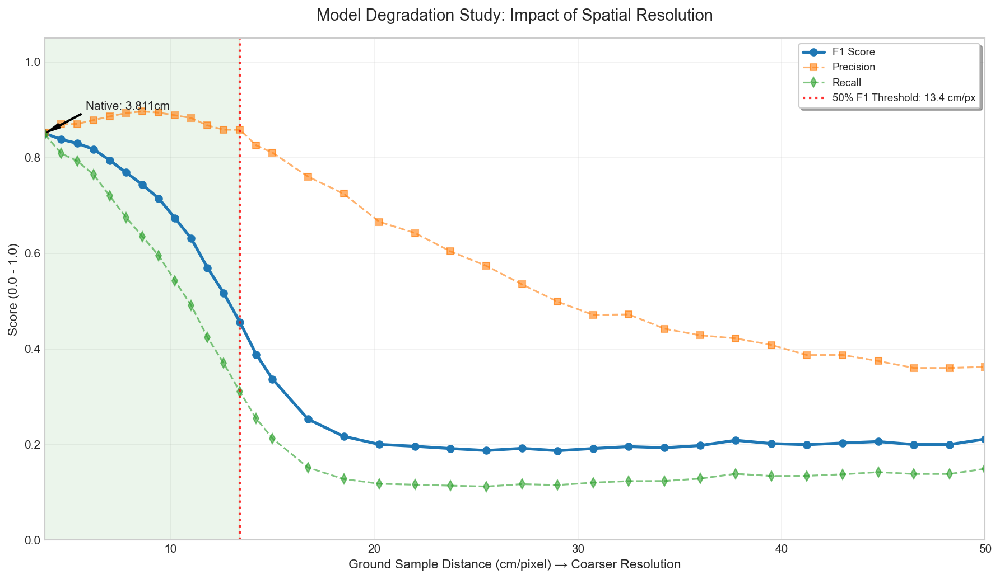

In [151]:
import pandas as pd
import matplotlib.pyplot as plt

# 4. Detailed Plotting
# Use the results from your high-density run
df_smooth = pd.DataFrame(results) # Assuming 'results' is the list from the full script

# --- Logic to find the 50% cutoff point ---
# We find the first resolution where F1 score falls below 0.5
cutoff_mask = df_smooth["f1"] < 0.5

if cutoff_mask.any():
    cutoff_res = round(df_smooth.loc[cutoff_mask, "res_cm"].iloc[0], 2)
else:
    # If it never drops below 0.5, use the max resolution tested
    cutoff_res = round(df_smooth["res_cm"].max(), 2)

plt.figure(figsize=(12, 7))

# Plot the metrics with markers to show the data points
plt.plot(df_smooth["res_cm"], df_smooth["f1"], 'o-', label="F1 Score", linewidth=2.5, markersize=6)
plt.plot(df_smooth["res_cm"], df_smooth["precision"], 's--', label="Precision", alpha=0.6)
plt.plot(df_smooth["res_cm"], df_smooth["recall"], 'd--', label="Recall", alpha=0.6)

# --- Enhanced Visual Cues ---

# High Performance Zone (Native Res to 50% Cutoff)
plt.axvspan(NATIVE_RES_CM, cutoff_res, color='green', alpha=0.08)

# Vertical line marking the 50% F1 drop-off
plt.axvline(cutoff_res, color='red', linestyle=':', linewidth=2, alpha=0.8, 
            label=f'50% F1 Threshold: {cutoff_res} cm/px')


# Annotate the Native Resolution
plt.annotate(f'Native: {NATIVE_RES_CM}cm', 
             xy=(NATIVE_RES_CM, df_smooth["f1"].iloc[0]), 
             xytext=(NATIVE_RES_CM+2, df_smooth["f1"].iloc[0]+0.05),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=4))

# Formatting
plt.title("Model Degradation Study: Impact of Spatial Resolution", fontsize=14, pad=15)
plt.xlabel("Ground Sample Distance (cm/pixel) → Coarser Resolution", fontsize=11)
plt.ylabel("Score (0.0 - 1.0)", fontsize=11)
plt.ylim(0, 1.05)
plt.xlim(NATIVE_RES_CM, MAX_RES_CM)
plt.legend(loc='upper right', frameon=True, shadow=True)
plt.grid(True, which="both", ls="-", alpha=0.3)

plt.tight_layout()
plt.show()

Illumination intensity

New images

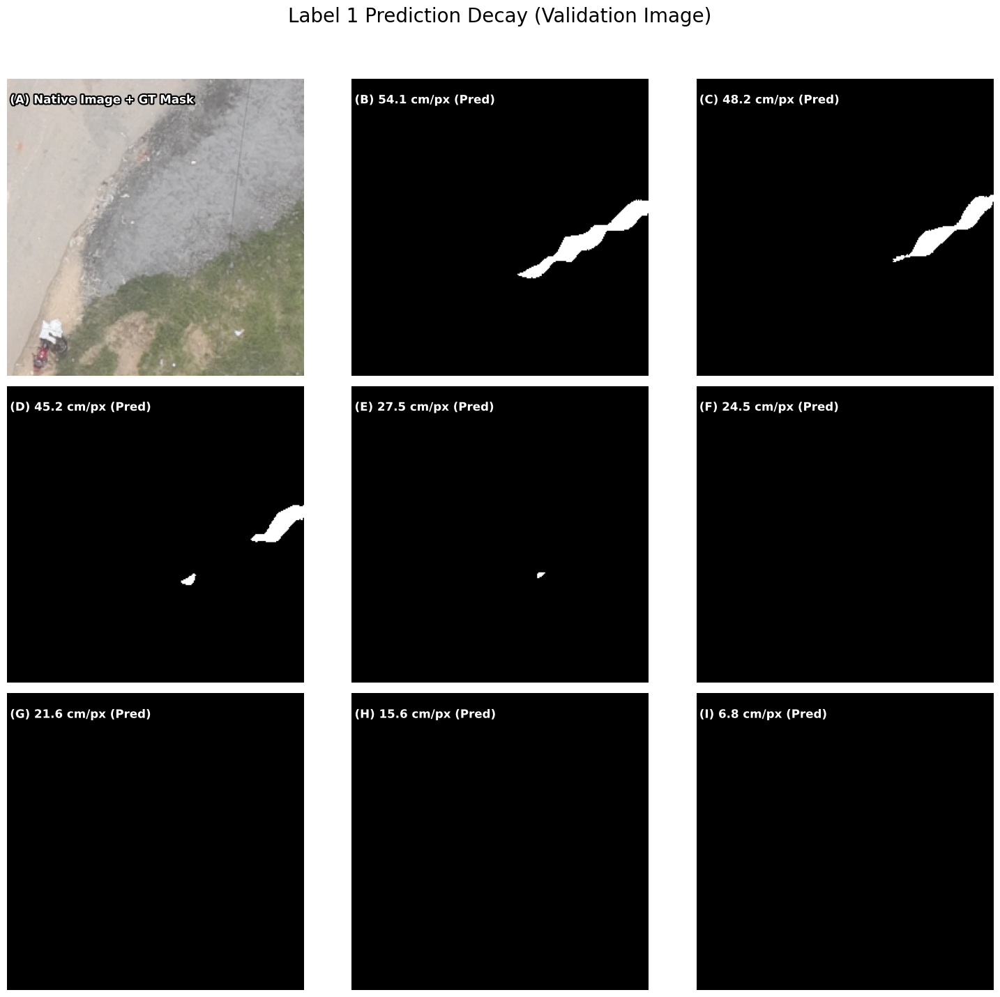

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import random
import tensorflow as tf

# 1. Get a random batch from the validation generator
random_batch_idx = random.randint(0, len(val_gen) - 1)
x_batch, y_batch = val_gen[random_batch_idx]

# Pick the first image in that batch
img_orig = x_batch[1]  # This is already normalized (0-1)
# Get the ground truth for Label 1 from the generator's one-hot mask
INTERNAL_IDX = LABEL_MAP[1]
gt_mask_label1 = (np.argmax(y_batch[0], axis=-1) == INTERNAL_IDX).astype(np.uint8)

# 2. Randomly sample 8 factors from our uniform res_factors list
# We sort them (reverse=True) so the grid goes from Fine -> Coarse
sample_indices = sorted(random.sample(range(0, len(res_factors)), 8), reverse=True)
selected_factors = [res_factors[i] for i in sample_indices]

# Letters for labeling
letters = "ABCDEFGHI"

def add_halo_text(ax, text, x=0.01, y=0.95, fontsize=12):
    ax.text(
        x, y, text, fontsize=fontsize, fontweight="bold", color="white",
        va="top", ha="left", transform=ax.transAxes, zorder=3,
        path_effects=[path_effects.withStroke(linewidth=3, foreground='black')]
    )

# Initialize 3x3 grid
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

# Slot A: Original Ground Truth for Label 1 (Native Resolution)
# We multiply img_orig by 255 because it came from the generator normalized
axes[0].imshow((img_orig * 255).astype(np.uint8))
# Overlay the GT mask in red to show where the target actually is
axes[0].imshow(gt_mask_label1, cmap='Reds', alpha=0.3) 
add_halo_text(axes[0], f"({letters[0]}) Native Image + GT Mask")
axes[0].axis("off")

# Slots B-I: Resolution decay predictions
for i, f in enumerate(selected_factors, start=1):
    # Calculate dimensions for this resolution
    h_low, w_low = int(256 * f), int(256 * f)
    
    # Simulate resolution drop
    img_low = tf.image.resize(img_orig, (max(1, h_low), max(1, w_low)), method="bilinear")
    x_input = tf.image.resize(img_low, (256, 256), method="bilinear")
    x_input = np.expand_dims(x_input, 0)

    # Inference
    pred = model.predict(x_input, verbose=0)[0]
    pred_class = np.argmax(pred, axis=-1)
    
    # Isolate Label 1
    pred_bin = (pred_class == INTERNAL_IDX).astype(np.uint8)

    # Compute actual cm/pixel
    res_cm = (NATIVE_RES_CM / f)
    
    # Display the prediction
    axes[i].imshow(pred_bin, cmap="gray")
    add_halo_text(axes[i], f"({letters[i]}) {res_cm:.1f} cm/px (Pred)")
    axes[i].axis("off")

plt.suptitle(f"Label 1 Prediction Decay (Validation Image)", fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [28]:
import os
import rasterio

# Get first image file in the directory
files = [f for f in os.listdir(IMG_DIR) if f.lower().endswith(('.tif', '.tiff', '.img', '.jp2', '.png', '.jpg'))]

if not files:
    print("No imagery files found in directory.")
else:
    img_path = os.path.join(IMG_DIR, files[0])
    print(f"Opening: {img_path}")

    with rasterio.open(img_path) as src:
        print("\n--- Image Info ---")
        print(f"Width (pixels):  {src.width}")
        print(f"Height (pixels): {src.height}")
        print(f"Bands:           {src.count}")
        print(f"CRS:             {src.crs}")
        
        # Spatial resolution (pixel size)
        res_x, res_y = src.res
        print(f"Pixel Size:      {res_x} x {res_y} {src.crs.linear_units if src.crs else 'units'}")
        
        print(f"Bounds:          {src.bounds}")


Opening: ../../data/tiled_data/images\clipped_image_100_tile_0_0.tif

--- Image Info ---
Width (pixels):  256
Height (pixels): 256
Bands:           4
CRS:             COMPD_CS["WGS 84 / UTM zone 36S + EGM96 height",PROJCS["WGS 84 / UTM zone 36S",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32736"]],VERT_CS["EGM96 height",VERT_DATUM["EGM96 geoid",2005,AUTHORITY["EPSG","5171"]],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Gravity-related height",UP],AUTHORITY["EPSG","5773"]]]